# Entropy, functions and hidden dependence

Exact finite distributions expose the chain rule, parity synergy and the effect of conditioning. These are proofs with numerical illustrations, not inference from a fitted model.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.information import (
    entropy,
    mutual_information,
    conditional_entropy,
    conditional_mutual_information,
)

joint = np.array([[0.25, 0.25], [0, 0.5]])
print(
    {
        "H(X)": entropy(joint.sum(1)),
        "H(X,Y)": entropy(joint),
        "H(X|Y)": conditional_entropy(joint),
        "I(X;Y)": mutual_information(joint),
    }
)
assert np.isclose(entropy(joint), entropy(joint.sum(0)) + conditional_entropy(joint))

{'H(X)': 1.0, 'H(X,Y)': 1.5, 'H(X|Y)': 0.6887218755408672, 'I(X;Y)': 0.31127812445913283}


A deterministic function cannot increase entropy. Equality requires invertibility on the supported source symbols. Merging two source labels gives a concrete strict example.

In [3]:
p = np.array([0.4, 0.3, 0.2, 0.1])
labels = np.array([0, 0, 1, 1])
function_p = np.bincount(labels, weights=p)
print("Before:", entropy(p), "bits; after merging labels:", entropy(function_p), "bits")

Before: 1.8464393446710154 bits; after merging labels: 0.8812908992306927 bits


In [4]:
from information_lab.sources import parity_law, project_law

x, p = parity_law(3)
xyz = project_law(x, p, [2, 2, 2])
print("Pairwise MI:", mutual_information(xyz.sum(2)))
print("Conditional MI given parity bit:", conditional_mutual_information(xyz))
identical = np.zeros((2, 2, 2))
identical[0, 0, 0] = identical[1, 1, 1] = 0.5
print(
    "X=Y=Z: MI",
    mutual_information(identical.sum(2)),
    "conditional MI",
    conditional_mutual_information(identical),
)

Pairwise MI: 0.0
Conditional MI given parity bit: 1.0
X=Y=Z: MI 1.0 conditional MI 0.0


**Recorded configuration**

{
  "family": "foundations",
  "id": "parity_10",
  "task": "parity",
  "variables": 10,
  "stochastic": false
}
{
  "pair_mi": 0.0,
  "conditional_mi": 0.0,
  "joint_to_last_mi": 1.0,
  "scope": "Pairwise independence can hide a perfect parity constraint. Conditioned MI can increase or decrease; it is not monotone under conditioning."
}


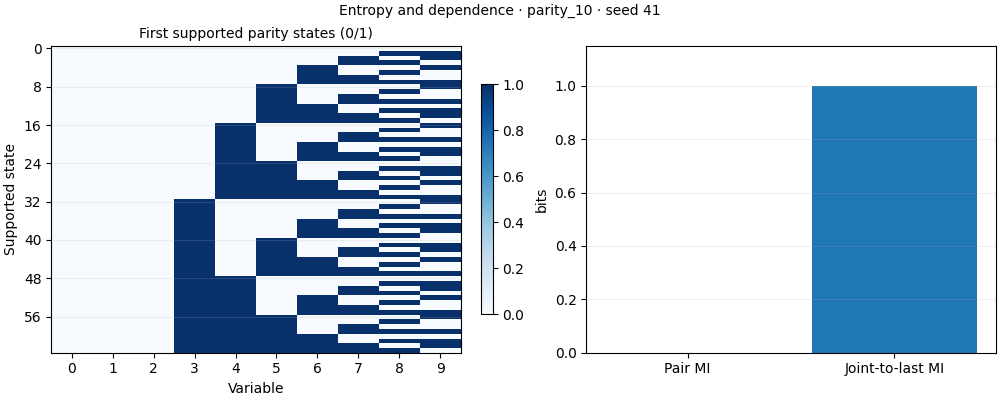

In [5]:
record, path = query("foundations", task="parity", variables=10)[0]
measured(record)
preview(record)

For n=10, every pair is independent, yet the first nine bits determine the last. This distinction is useful when pairwise diagnostics miss a higher-order constraint. The supplied strict concavity/convexity statements have explicit equality counterexamples in the course guide.